<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


MODEL COMPARISON
Model		Train Accuracy	Test Accuracy	Train-Test Gap
Baseline 	 0.979 		 0.883 		 0.096
L2 0.001 	 0.986 		 0.896 		 0.09
L2 0.01 	 0.953 		 0.865 		 0.088
L2 0.1 	 0.832 		 0.804 		 0.028
Dropout 0.2 	 0.986 		 0.883 		 0.102
Dropout 0.3 	 0.986 		 0.883 		 0.102
Dropout 0.5 	 0.979 		 0.883 		 0.096
Early Stopping 	 0.979 		 0.89 		 0.09


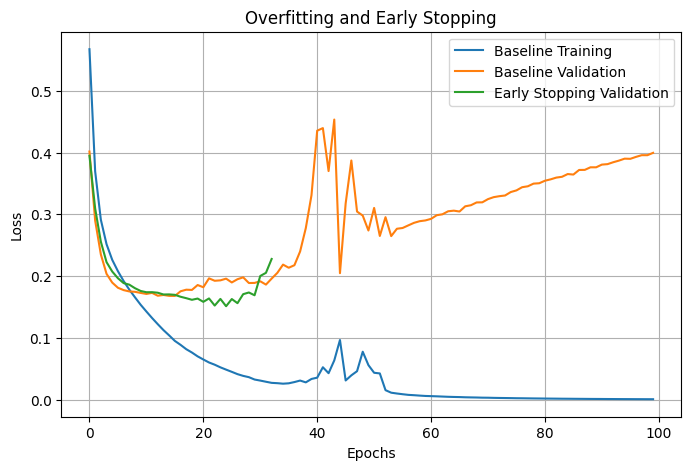

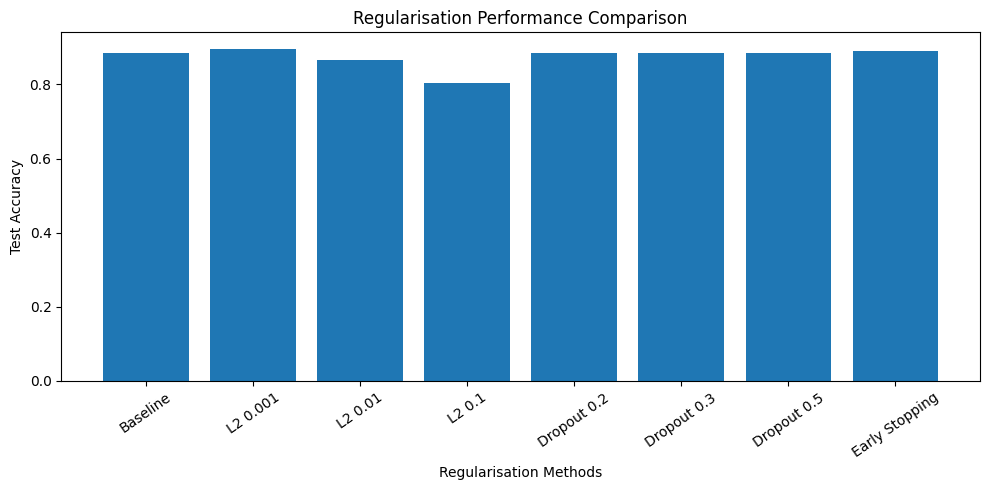

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

np.random.seed(42)
tf.random.set_seed(42)

# 1. Generate Diabetes-Style Dataset
X,Y = make_classification(
    n_samples=650,
    n_features=8,
    n_informative=5,
    n_redundant=2,
    n_classes=2,
    random_state=42
)

X_train,X_test,Y_train,Y_test = train_test_split(
    X,Y,test_size=0.25,
    random_state=42,
    stratify=Y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 2. Build Neural Network
def create_model(kind="baseline",value=0.0):

    if kind == "l2":
        regularizer = tf.keras.regularizers.l2(value)
    else:
        regularizer = None

    layers = [
        tf.keras.layers.Input(shape=(8,)),
        tf.keras.layers.Dense(
            128,activation='relu',
            kernel_regularizer=regularizer
        ),
        tf.keras.layers.Dense(
            128,activation='relu',
            kernel_regularizer=regularizer
        )
    ]

    # Dropout
    if kind == "dropout":
        layers.append(
            tf.keras.layers.Dropout(value)
        )

    layers.extend([
        tf.keras.layers.Dense(
            64,activation='relu',
            kernel_regularizer=regularizer
        ),
        tf.keras.layers.Dense(1,activation='sigmoid')
    ])

    model = tf.keras.Sequential(layers)

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

results = []

# Training and Evaluation Function
def train_model(name,kind="baseline",value=0.0,early=False):

    tf.keras.backend.clear_session()

    model = create_model(kind,value)

    callbacks = []

    if early:
        callbacks = [
            tf.keras.callbacks.EarlyStopping(
                monitor='val_loss',
                patience=8,
                restore_best_weights=True
            )
        ]

    history = model.fit(
        X_train,Y_train,
        validation_split=0.2,
        epochs=100,
        batch_size=16,
        verbose=0,
        callbacks=callbacks
    )

    train_acc = model.evaluate(
        X_train,Y_train,verbose=0
    )[1]

    test_acc = model.evaluate(
        X_test,Y_test,verbose=0
    )[1]

    gap = train_acc-test_acc

    results.append([
        name,train_acc,test_acc,gap
    ])

    return history.history

# 3. Baseline Model
baseline = train_model(
    "Baseline",
    "baseline"
)

# 4. L2 Regularisation
l2_histories = {}

for value in [0.001,0.01,0.1]:

    l2_histories[value] = train_model(
        "L2 "+str(value),
        "l2",
        value
    )

# 5. Dropout
dropout_histories = {}

for rate in [0.2,0.3,0.5]:

    dropout_histories[rate] = train_model(
        "Dropout "+str(rate),
        "dropout",
        rate
    )

# 6. Early Stopping
early_history = train_model(
    "Early Stopping",
    "baseline",
    early=True
)

# 7. Display Comparison Table
print("\nMODEL COMPARISON")
print("Model\t\tTrain Accuracy\tTest Accuracy\tTrain-Test Gap")

for row in results:

    print(
        row[0],"\t",
        round(row[1],3),"\t\t",
        round(row[2],3),"\t\t",
        round(row[3],3)
    )

# 8. Plot Baseline and Early Stopping Loss
plt.figure(figsize=(8,5))

plt.plot(
    baseline['loss'],
    label="Baseline Training"
)

plt.plot(
    baseline['val_loss'],
    label="Baseline Validation"
)

plt.plot(
    early_history['val_loss'],
    label="Early Stopping Validation"
)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Overfitting and Early Stopping")
plt.legend()
plt.grid()
plt.show()

# 9. Compare Test Accuracy
names = [row[0] for row in results]
accuracies = [row[2] for row in results]

plt.figure(figsize=(10,5))

plt.bar(names,accuracies)

plt.xlabel("Regularisation Methods")
plt.ylabel("Test Accuracy")
plt.title("Regularisation Performance Comparison")

plt.xticks(rotation=35)
plt.tight_layout()
plt.show()